# Cross-View Deep Integration: A Dual-Input PyTorch Framework for Concurrent CC and MLO Mammogram Classification

**Problem Statement**

Screening mammography relies on manual radiologist inspection, which is prone to high false-positive and false-negative rates due to structural noise, tissue overlap, and extreme visual subtlety.

Single-view Convolutional Neural Networks (CNNs) evaluate projection angles independently, missing the 3D anatomical context that radiologists use when cross-referencing features between CC and MLO views.

**Goal**

*To build an automated, dual-view deep learning pipeline in PyTorch that classifies mammograms into Benign or Malignant categories. By concurrently modeling spatial context from paired Craniocaudal (CC) and Mediolateral Oblique (MLO) views of the same breast, the framework overcomes the limitations of single-view computer vision systems and matches clinical diagnostic workflows.*

**STEPS INVOLVED**

*Activity 1:*

1.   Setting Up the Kaggle to Extract the Dataset directly
2.   Importing the libraries and setting them up
3. Locating the Folders
4. Parse CSV Metadata
5. Match DICOM Paths to JPG Files (Fixed Recursive Walk)
6. Robust Label Mapping, Organizing the Images into Folders
7. Dataset Summary
8. Visualizing Class Counts
9. Splitting the Dataset into : Training(70%), Validation(15%) and Testing(15%)
10. Class Weight Computation and PyTorch Dataset and Loaders
11. Shallow CNN Definition , Optimization SetUp, Generic Training Function
12. Training the Model, Evaluating The Validation and the Test Set
13. Confusion Matrix
14. Misclassification Count



In [ ]:
import os
import zipfile

!pip install -q kaggle
!kaggle datasets download -d awsaf49/cbis-ddsm-breast-cancer-image-dataset -p /content/

zip_path = "/content/cbis-ddsm-breast-cancer-image-dataset.zip"
if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall("/content/cbis_ddsm")
    print("Dataset successfully extracted.")
else:
    print("Zip file not found. Ensure Kaggle API credentials are configured.")

Dataset URL: https://www.kaggle.com/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset
License(s): CC-BY-SA-3.0
100% 4.95G/4.95G [00:31<00:00, 167MB/s]

Dataset Successfully extracted


In [ ]:
import os
import glob
import shutil
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

DATA_ROOT = "/content/cbis_ddsm"

Using device: cpu
['jpeg', 'csv']


In [ ]:
def find_dir(root, name):
    for dirpath, dirnames, _ in os.walk(root):
        if name in dirnames:
            return os.path.join(dirpath, name)
    raise FileNotFoundError(f"Could not find a '{name}' folder under {root}")

CSV_DIR = find_dir(DATA_ROOT, "csv")
JPEG_DIR = find_dir(DATA_ROOT, "jpeg")
print("CSV_DIR :", CSV_DIR)
print("JPEG_DIR:", JPEG_DIR)

CSV_DIR : /content/cbis_ddsm/csv
JPEG_DIR: /content/cbis_ddsm/jpeg
['mass_case_description_test_set.csv', 'meta.csv', 'dicom_info.csv', 'mass_case_description_train_set.csv', 'calc_case_description_test_set.csv', 'calc_case_description_train_set.csv']


In [ ]:
csv_files = {
    "calc_train": "calc_case_description_train_set.csv",
    "calc_test":  "calc_case_description_test_set.csv",
    "mass_train": "mass_case_description_train_set.csv",
    "mass_test":  "mass_case_description_test_set.csv",
}

frames = []
for tag, fname in csv_files.items():
    fpath = os.path.join(CSV_DIR, fname)
    if os.path.exists(fpath):
        df = pd.read_csv(fpath)
        df["source_set"] = tag
        frames.append(df)

meta_df_raw = pd.concat(frames, ignore_index=True)
meta_df_raw.columns = [c.strip().lower().replace(" ", "_") for c in meta_df_raw.columns]

# Flatten path columns to include full, cropped, and ROI mask images
path_cols = [c for c in meta_df_raw.columns if "path" in c or "file" in c]
id_vars = [c for c in meta_df_raw.columns if c not in path_cols]

meta_df = pd.melt(
    meta_df_raw,
    id_vars=id_vars,
    value_vars=path_cols,
    var_name="image_type",
    value_name="image_file_path"
)

meta_df = meta_df.dropna(subset=["image_file_path"]).reset_index(drop=True)
print(f"Expanded Metadata shape: {meta_df.shape}")

Loaded CSV shape: (3568, 18)


,patient_id,left_or_right_breast,image_view,pathology,image_file_path
0,P_00005,RIGHT,CC,MALIGNANT,Calc-Training_P_00005_RIGHT_CC/1.3.6.1.4.1.959...
1,P_00005,RIGHT,MLO,MALIGNANT,Calc-Training_P_00005_RIGHT_MLO/1.3.6.1.4.1.95...
2,P_00007,LEFT,CC,BENIGN,Calc-Training_P_00007_LEFT_CC/1.3.6.1.4.1.9590...
3,P_00007,LEFT,MLO,BENIGN,Calc-Training_P_00007_LEFT_MLO/1.3.6.1.4.1.959...
4,P_00008,LEFT,CC,BENIGN_WITHOUT_CALLBACK,Calc-Training_P_00008_LEFT_CC/1.3.6.1.4.1.9590...


In [ ]:
series_to_jpgs = {}
for root, _, files in os.walk(JPEG_DIR):
    jpgs = [os.path.join(root, f) for f in files if f.lower().endswith(('.jpg', '.jpeg'))]
    if jpgs:
        folder_name = os.path.basename(root)
        series_to_jpgs[folder_name] = jpgs
        parent_folder = os.path.basename(os.path.dirname(root))
        if parent_folder and parent_folder not in series_to_jpgs:
            series_to_jpgs[parent_folder] = jpgs

def resolve_full_image(dicom_path):
    if not isinstance(dicom_path, str):
        return None
    parts = [p for p in dicom_path.split("/") if p]
    for part in parts:
        if part in series_to_jpgs:
            candidates = series_to_jpgs[part]
            candidates = sorted(candidates, key=lambda p: os.path.getsize(p), reverse=True)
            return candidates[0]
    return None

meta_df["resolved_path"] = meta_df["image_file_path"].apply(resolve_full_image)
meta_df = meta_df[meta_df["resolved_path"].notna()].reset_index(drop=True)
print(f"Resolved {len(meta_df)} valid image paths on disk.")

In [ ]:
PATHOLOGY_MAP = {
    "BENIGN": "Benign",
    "BENIGN_WITHOUT_CALLBACK": "Benign",
    "MALIGNANT": "Malignant",
}

def map_label(p):
    key = str(p).strip().upper().replace(" ", "_")
    return PATHOLOGY_MAP[key]

meta_df = meta_df[meta_df["pathology"].notna()].reset_index(drop=True)
meta_df["label"] = meta_df["pathology"].apply(map_label)
meta_df = meta_df.drop_duplicates(subset=["resolved_path"]).reset_index(drop=True)

In [ ]:
CLASS_ROOT = "/content/dataset"
for cls in ["Benign", "Malignant"]:
    os.makedirs(os.path.join(CLASS_ROOT, cls), exist_ok=True)

image_records = []
for i, row in meta_df.iterrows():
    src = row["resolved_path"]
    cls = row["label"]
    dst_name = f"{row.get('patient_id','P')}_{row.get('left_or_right_breast','NA')}_{row.get('image_view','NA')}_{i}.jpg"
    dst = os.path.join(CLASS_ROOT, cls, dst_name)
    if not os.path.exists(dst):
        try:
            shutil.copyfile(src, dst)
        except Exception:
            continue
    image_records.append({"path": dst, "label": cls})

image_df = pd.DataFrame(image_records)
print(f"Total of {len(image_df)} images organized.")

Resolved 3568 / 3568 images to a jpg on disk


In [ ]:
class_names = sorted(image_df["label"].unique())

plt.figure(figsize=(6, 4))
sns.countplot(data=image_df, x="label", order=class_names)
plt.title("Images per Class")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

Raw pathology value counts:
pathology
MALIGNANT                  1457
BENIGN                     1429
BENIGN_WITHOUT_CALLBACK     682
Name: count, dtype: int64
Dropped 0 rows with missing pathology

Mapped label value counts:
label
Benign       1739
Malignant    1364
Name: count, dtype: int64


In [ ]:
CLASS_ROOT = "/content/dataset"
for cls in ["Benign", "Malignant"]:
    os.makedirs(os.path.join(CLASS_ROOT, cls), exist_ok=True)

image_records = []
for i, row in meta_df.iterrows():
    src = row["resolved_path"]
    cls = row["label"]
    dst_name = f"{row['patient_id']}_{row.get('left_or_right_breast','NA')}_{row.get('image_view','NA')}_{i}.jpg"
    dst = os.path.join(CLASS_ROOT, cls, dst_name)
    if not os.path.exists(dst):
        try:
            shutil.copyfile(src, dst)
        except Exception:
            continue
    image_records.append({"path": dst, "label": cls})

image_df = pd.DataFrame(image_records)
print(f"{len(image_df)} images organized into class folders")
image_df.head()

3103 images organized into class folders


,path,label
0,/content/dataset/Malignant/P_00005_RIGHT_CC_0.jpg,Malignant
1,/content/dataset/Malignant/P_00005_RIGHT_MLO_1...,Malignant
2,/content/dataset/Benign/P_00007_LEFT_CC_2.jpg,Benign
3,/content/dataset/Benign/P_00007_LEFT_MLO_3.jpg,Benign
4,/content/dataset/Benign/P_00008_LEFT_CC_4.jpg,Benign


In [ ]:
class_names = sorted(image_df["label"].unique())
num_classes = len(class_names)

assert class_names == ["Benign", "Malignant"], f"Expected 2 classes, got: {class_names}"

summary_table = image_df["label"].value_counts().rename_axis("Class").reset_index(name="Number of Images")
total_row = pd.DataFrame([{"Class": "Total", "Number of Images": summary_table["Number of Images"].sum()}])
summary_table = pd.concat([summary_table, total_row], ignore_index=True)

print(f"Number of classes: {num_classes}")
print(f"Classes: {class_names}")
summary_table

Number of classes: 2
Classes: ['Benign', 'Malignant']


,Class,Number of Images
0,Benign,1739
1,Malignant,1364
2,Total,3103


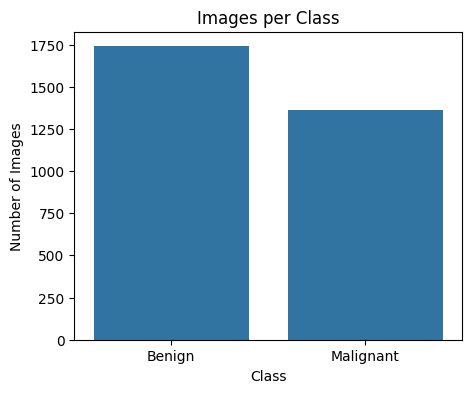

In [ ]:
plt.figure(figsize=(5, 4))
sns.countplot(data=image_df, x="label", order=class_names)
plt.title("Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

In [ ]:
train_df, temp_df = train_test_split(
    image_df, test_size=0.30, stratify=image_df["label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED
)

split_table = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Num Images": [len(train_df), len(val_df), len(test_df)]
})
split_table

,Split,Num Images
0,Train,2172
1,Validation,465
2,Test,466


In [ ]:
label_to_idx = {c: i for i, c in enumerate(class_names)}
idx_to_label = {i: c for c, i in label_to_idx.items()}

class_counts = train_df["label"].value_counts().to_dict()
n_total = sum(class_counts.values())
class_weights = torch.tensor(
    [n_total / (num_classes * class_counts.get(c, 1)) for c in class_names],
    dtype=torch.float32
).to(DEVICE)
print("Class weights:", dict(zip(class_names, class_weights.tolist())))

Class weights: {'Benign': 0.8923582434654236, 'Malignant': 1.137172818183899}


In [ ]:
IMG_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class MammogramDataset(Dataset):
    def __init__(self, df, transform):
        self.paths = df["path"].tolist()
        self.labels = [label_to_idx[l] for l in df["label"].tolist()]
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        img = self.transform(img)
        return img, self.labels[idx]

BATCH_SIZE = 32

train_ds = MammogramDataset(train_df, train_transform)
val_ds   = MammogramDataset(val_df, eval_transform)
test_ds  = MammogramDataset(test_df, eval_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Dataset splits: Train={len(train_ds)}, Val={len(val_ds)}, Test={len(test_ds)}")

Dataset splits: Train=2172, Val=465, Test=466


In [ ]:
class ShallowCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 28 * 28, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

shallow_model = ShallowCNN(num_classes=num_classes).to(DEVICE)
print(shallow_model)

ShallowCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=50176, out_features=128, bias=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)


In [ ]:
EPOCHS = 15
LEARNING_RATE = 1e-3

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer_shallow = optim.SGD(shallow_model.parameters(), lr=LEARNING_RATE, momentum=0.9)
scheduler_shallow = optim.lr_scheduler.CosineAnnealingLR(optimizer_shallow, T_max=EPOCHS)

In [ ]:
def train_model(model, criterion, optimizer, scheduler, train_loader, val_loader,
                 epochs=EPOCHS, device=DEVICE, use_amp=True):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    scaler_enabled = use_amp and device.type == "cuda"
    scaler = torch.amp.GradScaler('cuda', enabled=scaler_enabled)

    for epoch in range(epochs):
        model.train()
        running_loss, running_correct, n = 0.0, 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()

            with torch.amp.autocast('cuda', enabled=scaler_enabled):
                outputs = model(imgs)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * imgs.size(0)
            running_correct += (outputs.argmax(1) == labels).sum().item()
            n += imgs.size(0)

        train_loss = running_loss / n
        train_acc = running_correct / n

        model.eval()
        v_loss, v_correct, v_n = 0.0, 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = model(imgs)
                loss = criterion(outputs, labels)
                v_loss += loss.item() * imgs.size(0)
                v_correct += (outputs.argmax(1) == labels).sum().item()
                v_n += imgs.size(0)

        val_loss = v_loss / v_n
        val_acc = v_correct / v_n

        if scheduler is not None:
            scheduler.step()

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch+1:02d}/{epochs} | "
              f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
              f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}")

    return history


def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], label="Train")
    axes[0].plot(history["val_loss"], label="Validation")
    axes[0].set_title(f"{title} — Loss")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()

    axes[1].plot(history["train_acc"], label="Train")
    axes[1].plot(history["val_acc"], label="Validation")
    axes[1].set_title(f"{title} — Accuracy")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
    plt.tight_layout()
    plt.show()

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 01/15 | train_loss=0.6962 train_acc=0.5032 | val_loss=0.6983 val_acc=0.4387
Epoch 02/15 | train_loss=0.6960 train_acc=0.4945 | val_loss=0.6913 val_acc=0.4989
Epoch 03/15 | train_loss=0.6913 train_acc=0.5428 | val_loss=0.6901 val_acc=0.5613
Epoch 04/15 | train_loss=0.6924 train_acc=0.5290 | val_loss=0.6901 val_acc=0.5376
Epoch 05/15 | train_loss=0.6897 train_acc=0.5562 | val_loss=0.6890 val_acc=0.5957
Epoch 06/15 | train_loss=0.6889 train_acc=0.5552 | val_loss=0.6881 val_acc=0.5591
Epoch 07/15 | train_loss=0.6895 train_acc=0.5378 | val_loss=0.6874 val_acc=0.5398
Epoch 08/15 | train_loss=0.6884 train_acc=0.5470 | val_loss=0.6875 val_acc=0.5656
Epoch 09/15 | train_loss=0.6875 train_acc=0.5580 | val_loss=0.6871 val_acc=0.5570
Epoch 10/15 | train_loss=0.6882 train_acc=0.5442 | val_loss=0.6883 val_acc=0.5548
Epoch 11/15 | train_loss=0.6876 train_acc=0.5511 | val_loss=0.6880 val_acc=0.5677
Epoch 12/15 | train_loss=0.6862 train_acc=0.5525 | val_loss=0.6873 val_acc=0.5634
Epoch 13/15 | tr

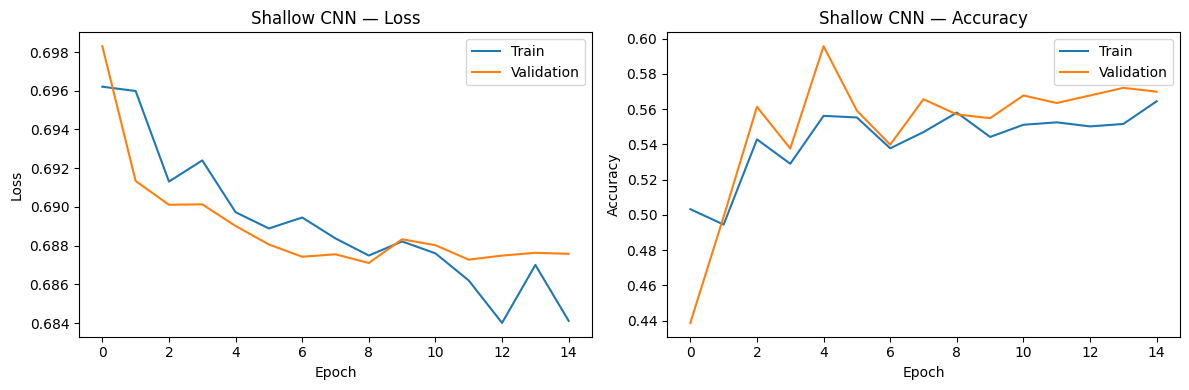

In [ ]:
history_shallow = train_model(
    shallow_model, criterion, optimizer_shallow, scheduler_shallow,
    train_loader, val_loader, epochs=EPOCHS
)
plot_history(history_shallow, "Shallow CNN")

In [ ]:
def evaluate(model, loader, device=DEVICE):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            outputs = model(imgs)
            preds = outputs.argmax(1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())
    acc = accuracy_score(all_labels, all_preds)
    return acc, np.array(all_labels), np.array(all_preds)

val_acc_shallow, val_labels_shallow, val_preds_shallow = evaluate(shallow_model, val_loader)
print(f"Shallow CNN — Validation accuracy: {val_acc_shallow:.4f}")

Shallow CNN — Validation accuracy: 0.5699


In [ ]:
test_acc_shallow, test_labels_shallow, test_preds_shallow = evaluate(shallow_model, test_loader)
print(f"Shallow CNN — Test accuracy: {test_acc_shallow:.4f}")

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Shallow CNN — Test accuracy: 0.5708


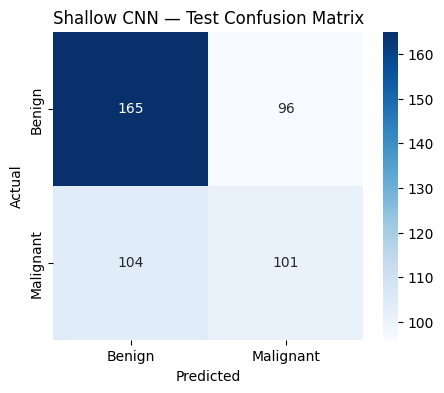

              precision    recall  f1-score   support

      Benign       0.61      0.63      0.62       261
   Malignant       0.51      0.49      0.50       205

    accuracy                           0.57       466
   macro avg       0.56      0.56      0.56       466
weighted avg       0.57      0.57      0.57       466



In [ ]:
def show_confusion_matrix(y_true, y_pred, class_names, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    print(classification_report(y_true, y_pred, target_names=class_names))
    return cm

cm_shallow = show_confusion_matrix(
    test_labels_shallow, test_preds_shallow, class_names, "Shallow CNN — Test Confusion Matrix"
)

In [ ]:
misclassified_idx = np.where(test_labels_shallow != test_preds_shallow)[0]
misclassified_df = test_df.reset_index(drop=True).iloc[misclassified_idx].copy()
misclassified_df["predicted"] = [idx_to_label[p] for p in test_preds_shallow[misclassified_idx]]
print(f"{len(misclassified_df)} / {len(test_df)} test images misclassified")
misclassified_df.head(10)

200 / 466 test images misclassified


,path,label,predicted
7,/content/dataset/Malignant/P_01481_RIGHT_CC_24...,Malignant,Benign
11,/content/dataset/Benign/P_01182_LEFT_MLO_2269.jpg,Benign,Malignant
12,/content/dataset/Benign/P_01616_RIGHT_MLO_993.jpg,Benign,Malignant
15,/content/dataset/Malignant/P_01582_LEFT_MLO_98...,Malignant,Benign
16,/content/dataset/Benign/P_01395_RIGHT_CC_3015.jpg,Benign,Malignant
19,/content/dataset/Benign/P_00353_LEFT_MLO_1278.jpg,Benign,Malignant
24,/content/dataset/Benign/P_01716_RIGHT_MLO_3073...,Benign,Malignant
25,/content/dataset/Malignant/P_02079_RIGHT_MLO_2...,Malignant,Benign
30,/content/dataset/Benign/P_00131_LEFT_CC_2762.jpg,Benign,Malignant
32,/content/dataset/Benign/P_01478_RIGHT_MLO_927.jpg,Benign,Malignant


# Activity 2: Transfer Learning

**STEPS INVOLVED**
1. Build AlexNet
2. Train AlexNet
3. Evaluate AlexNet
4. Optimizer Comparison Suite (SGD, SGDM, ADAM, RMSPROP)
5. Optimizer Plot
6. Grad-CAM Explainability (Gradient Track Fixed)

In [ ]:
def build_alexnet(num_classes=2, freeze_features=False):
    model = models.alexnet(weights=models.AlexNet_Weights.IMAGENET1K_V1)
    if freeze_features:
        for param in model.features.parameters():
            param.requires_grad = False
    in_features = model.classifier[6].in_features
    model.classifier[6] = nn.Linear(in_features, num_classes)
    return model.to(DEVICE)

alexnet_model = build_alexnet(num_classes=num_classes, freeze_features=False)
print(alexnet_model.classifier)

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:06<00:00, 36.3MB/s]


Sequential(
  (0): Dropout(p=0.5, inplace=False)
  (1): Linear(in_features=9216, out_features=4096, bias=True)
  (2): ReLU(inplace=True)
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=4096, out_features=4096, bias=True)
  (5): ReLU(inplace=True)
  (6): Linear(in_features=4096, out_features=2, bias=True)
)


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 01/10 | train_loss=0.7042 train_acc=0.5529 | val_loss=0.6733 val_acc=0.5785
Epoch 02/10 | train_loss=0.6732 train_acc=0.5925 | val_loss=0.6905 val_acc=0.6043
Epoch 03/10 | train_loss=0.6648 train_acc=0.5985 | val_loss=0.6568 val_acc=0.6108
Epoch 04/10 | train_loss=0.6510 train_acc=0.6174 | val_loss=0.6533 val_acc=0.5978
Epoch 05/10 | train_loss=0.6521 train_acc=0.6234 | val_loss=0.6485 val_acc=0.6172
Epoch 06/10 | train_loss=0.6530 train_acc=0.6100 | val_loss=0.6502 val_acc=0.6065
Epoch 07/10 | train_loss=0.6400 train_acc=0.6225 | val_loss=0.6491 val_acc=0.6108
Epoch 08/10 | train_loss=0.6341 train_acc=0.6257 | val_loss=0.6466 val_acc=0.6086
Epoch 09/10 | train_loss=0.6399 train_acc=0.6183 | val_loss=0.6469 val_acc=0.6065
Epoch 10/10 | train_loss=0.6370 train_acc=0.6312 | val_loss=0.6467 val_acc=0.6022


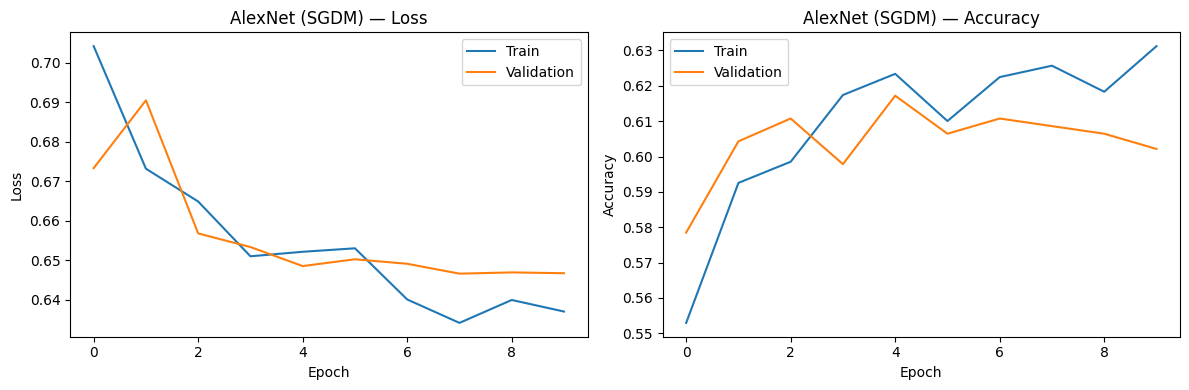

In [ ]:
EPOCHS_TL = 10
optimizer_alexnet = optim.SGD(alexnet_model.parameters(), lr=1e-4, momentum=0.9)
scheduler_alexnet = optim.lr_scheduler.CosineAnnealingLR(optimizer_alexnet, T_max=EPOCHS_TL)

history_alexnet = train_model(
    alexnet_model, criterion, optimizer_alexnet, scheduler_alexnet,
    train_loader, val_loader, epochs=EPOCHS_TL
)
plot_history(history_alexnet, "AlexNet (SGDM)")

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


AlexNet — Validation accuracy: 0.6022
AlexNet — Test accuracy: 0.6245


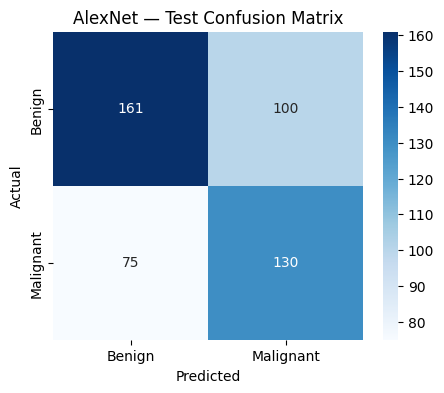

              precision    recall  f1-score   support

      Benign       0.68      0.62      0.65       261
   Malignant       0.57      0.63      0.60       205

    accuracy                           0.62       466
   macro avg       0.62      0.63      0.62       466
weighted avg       0.63      0.62      0.63       466



In [ ]:
val_acc_alexnet, val_labels_alexnet, val_preds_alexnet = evaluate(alexnet_model, val_loader)
test_acc_alexnet, test_labels_alexnet, test_preds_alexnet = evaluate(alexnet_model, test_loader)
print(f"AlexNet — Validation accuracy: {val_acc_alexnet:.4f}")
print(f"AlexNet — Test accuracy: {test_acc_alexnet:.4f}")

cm_alexnet = show_confusion_matrix(
    test_labels_alexnet, test_preds_alexnet, class_names, "AlexNet — Test Confusion Matrix"
)

In [ ]:
def make_optimizer(name, params, lr):
    if name == "SGD":
        return optim.SGD(params, lr=lr)
    if name == "SGDM":
        return optim.SGD(params, lr=lr, momentum=0.9)
    if name == "Adam":
        return optim.Adam(params, lr=lr)
    if name == "RMSProp":
        return optim.RMSprop(params, lr=lr)
    raise ValueError(name)

EPOCHS_COMPARE = 5
optimizer_names = ["SGD", "SGDM", "Adam", "RMSProp"]
comparison_results = []
comparison_histories = {}

for opt_name in optimizer_names:
    print(f"\n=== Training AlexNet with {opt_name} ===")
    model_i = build_alexnet(num_classes=num_classes, freeze_features=False)
    opt_i = make_optimizer(opt_name, model_i.parameters(), lr=1e-4)
    hist_i = train_model(model_i, criterion, opt_i, scheduler=None,
                          train_loader=train_loader, val_loader=val_loader,
                          epochs=EPOCHS_COMPARE)
    comparison_histories[opt_name] = hist_i
    final_val_acc = hist_i["val_acc"][-1]
    comparison_results.append({"Optimizer": opt_name, "Final Val Accuracy": final_val_acc})

comparison_table = pd.DataFrame(comparison_results).sort_values(
    "Final Val Accuracy", ascending=False
).reset_index(drop=True)
comparison_table


=== Training AlexNet with SGD ===


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 01/5 | train_loss=0.7223 train_acc=0.5106 | val_loss=0.7016 val_acc=0.5011
Epoch 02/5 | train_loss=0.7050 train_acc=0.5184 | val_loss=0.6959 val_acc=0.5161
Epoch 03/5 | train_loss=0.6942 train_acc=0.5355 | val_loss=0.6880 val_acc=0.5355
Epoch 04/5 | train_loss=0.6928 train_acc=0.5428 | val_loss=0.6835 val_acc=0.5333
Epoch 05/5 | train_loss=0.6911 train_acc=0.5442 | val_loss=0.6792 val_acc=0.5548

=== Training AlexNet with SGDM ===
Epoch 01/5 | train_loss=0.6979 train_acc=0.5571 | val_loss=0.6821 val_acc=0.5699
Epoch 02/5 | train_loss=0.6653 train_acc=0.5916 | val_loss=0.6670 val_acc=0.5656
Epoch 03/5 | train_loss=0.6513 train_acc=0.6123 | val_loss=0.6551 val_acc=0.6022
Epoch 04/5 | train_loss=0.6461 train_acc=0.6151 | val_loss=0.6578 val_acc=0.6043
Epoch 05/5 | train_loss=0.6466 train_acc=0.6308 | val_loss=0.6659 val_acc=0.6065

=== Training AlexNet with Adam ===
Epoch 01/5 | train_loss=0.6808 train_acc=0.5810 | val_loss=0.7133 val_acc=0.5785
Epoch 02/5 | train_loss=0.6423 train_

,Optimizer,Final Val Accuracy
0,Adam,0.649462
1,SGDM,0.606452
2,SGD,0.554839
3,RMSProp,0.550538


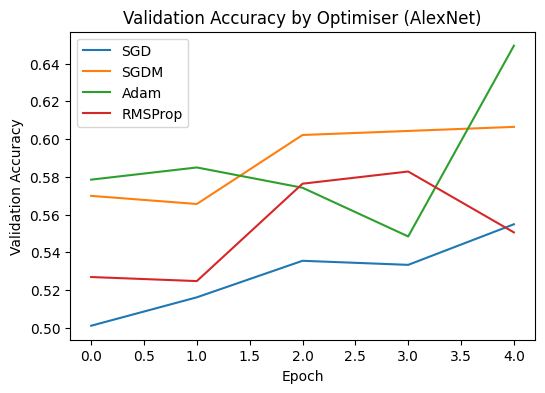

Best optimiser on validation set: Adam


In [ ]:
plt.figure(figsize=(6, 4))
for name, hist in comparison_histories.items():
    plt.plot(hist["val_acc"], label=name)
plt.title("Validation Accuracy by Optimiser (AlexNet)")
plt.xlabel("Epoch"); plt.ylabel("Validation Accuracy"); plt.legend()
plt.show()

best_optimizer = comparison_table.iloc[0]["Optimizer"]
print("Best optimiser on validation set:", best_optimizer)

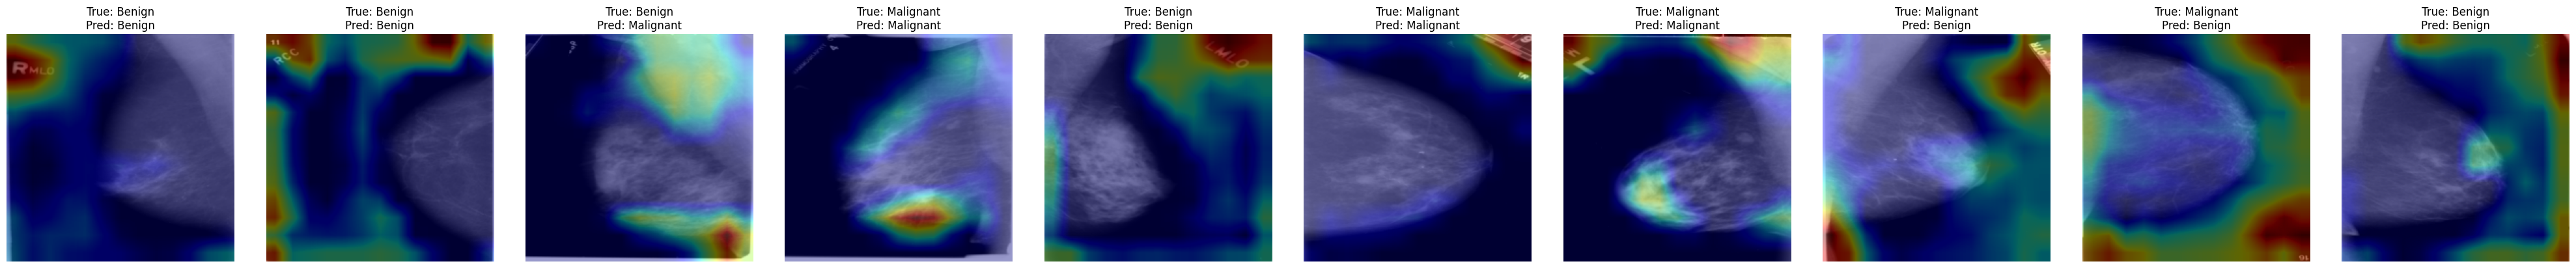

In [ ]:
def grad_cam(model, img_tensor, target_layer, class_idx=None):
    model.eval()
    activations = {}
    gradients = {}

    def fwd_hook(module, inp, out):
        activations["value"] = out

    def bwd_hook(module, grad_in, grad_out):
        gradients["value"] = grad_out[0]

    h1 = target_layer.register_forward_hook(fwd_hook)
    h2 = target_layer.register_full_backward_hook(bwd_hook)

    img_input = img_tensor.unsqueeze(0).to(DEVICE).clone().detach()
    img_input.requires_grad = True

    output = model(img_input)
    if class_idx is None:
        class_idx = output.argmax(dim=1).item()

    model.zero_grad()
    output[0, class_idx].backward()

    grads = gradients["value"][0].detach()
    acts = activations["value"][0].detach()
    weights = grads.mean(dim=(1, 2))

    cam = torch.zeros(acts.shape[1:], dtype=torch.float32).to(DEVICE)
    for i, w in enumerate(weights):
        cam += w * acts[i]
    cam = torch.relu(cam)
    cam = cam / (cam.max() + 1e-8)

    h1.remove()
    h2.remove()
    return cam.cpu().numpy(), class_idx


def show_grad_cam(model, dataset, target_layer, n=3):
    fig, axes = plt.subplots(1, n, figsize=(4*n, 4))
    if n == 1:
        axes = [axes]
    idxs = random.sample(range(len(dataset)), n)
    for ax, idx in zip(axes, idxs):
        img_tensor, label = dataset[idx]
        cam, pred_idx = grad_cam(model, img_tensor, target_layer)

        img_np = img_tensor.permute(1, 2, 0).numpy()
        img_np = img_np * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
        img_np = np.clip(img_np, 0, 1)

        cam_pil = Image.fromarray((cam * 255).astype(np.uint8))
        cam_resized = np.array(cam_pil.resize((img_np.shape[1], img_np.shape[0]), resample=Image.BILINEAR))

        ax.imshow(img_np)
        ax.imshow(cam_resized, cmap="jet", alpha=0.4)
        ax.set_title(f"True: {idx_to_label[label]}\nPred: {idx_to_label[pred_idx]}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

def replace_inplace_relu(model):
    for child_name, child in model.named_children():
        if isinstance(child, nn.ReLU) and child.inplace:
            # Replace in-place ReLU with non-in-place version
            setattr(model, child_name, nn.ReLU(inplace=False))
        else:
            # Recursively apply to children modules
            replace_inplace_relu(child)

# Apply the fix to AlexNet model before using Grad-CAM
replace_inplace_relu(alexnet_model)

last_conv_layer = alexnet_model.features[-3]
show_grad_cam(alexnet_model, test_ds, last_conv_layer, n=10)